hi.


TRACK: AI + CLIMATE

my challenge. Build an AI tool that helps a community, a city or an energy system measure,
predict or reduce its climate impact.

Time series data -> data recorded at regular times, such as each 24 hrs
_____________________________

- renewable energy predictyion
- based on weather data
- Hackathon suggests:
   - next-day weather forecast
   - next-day solar energy forecast
   - land-use mapping from satilite data
   - largest emmiters and predict smth

do specific cities rather than whole world

-----------------------------

 - "Our project helps [city people] by taking [past data] and giving back [the predicted air quality]."

leets start building!

install scikit-learn into the environment. only needs to be done wonce.

In [ ]:
#%pip install scikit-learn

INPUT: the weather data from the 3 previous days
OUTPUT: a number, representing the predicted air quality.


import the libs we r gonna use
  [sklearn] or [pytorch]?
start with [sklearn] because why not.
also THE WHEEL decided skelarn

In [212]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from csv import reader
from pickle import dump

In [213]:
with open("data/edited_data.csv", mode='r') as file:
    raw_data = list(reader(file))[1:]


answers = [float(raw_data[i][0]) for i in range(3, 406)]
for i in range(410, len(raw_data)):
    answers.append(float(raw_data[i][0]))

datas = []
for i in range(2): # repeat twice
    if i == 0:
        r = range(403)
    else:
        r = range(407, len(raw_data)-3)
    for row in r:
        datas.append((
            float(raw_data[row][0]),
            int(raw_data[row][1]),
            #float(raw_data[row][2]),
            #float(raw_data[row][3]),
            #float(raw_data[row][4]),
            float(raw_data[row][5]),
            float(raw_data[row][6]),

            float(raw_data[row+1][0]),
            int(raw_data[row+1][1]),
            #float(raw_data[row+1][2]),
            #float(raw_data[row+1][3]),
            #float(raw_data[row+1][4]),
            float(raw_data[row+1][5]),
            float(raw_data[row+1][6]),

            float(raw_data[row+2][0]),
            int(raw_data[row+2][1]),
            #float(raw_data[row+2][2]), 
            #float(raw_data[row+2][3]),
            #float(raw_data[row+2][4]),
            float(raw_data[row+2][5]),
            float(raw_data[row+2][6])
        )) # could have used a loop, easier to not.


load and scale the data

In [214]:
train_values, test_values, train_answers, test_answers = train_test_split(datas, answers, test_size=0.2)
scaler = StandardScaler()

train_values = scaler.fit_transform(train_values)

# scale the testing values the same as the training values
test_values = scaler.transform(test_values)

does it work?

In [215]:
model = LinearRegression()

#train the model
model.fit(train_values, train_answers)

#make predictions
preds = model.predict(test_values)
preds *= 1.1
#evaluate model
r2 = r2_score(test_answers, preds)
mae = mean_absolute_error(test_answers, preds)
rmse = root_mean_squared_error(test_answers, preds)

print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

R2 Score: 0.7098
MAE: 1.8796
RMSE: 2.3212


ITS ALIVE!!!

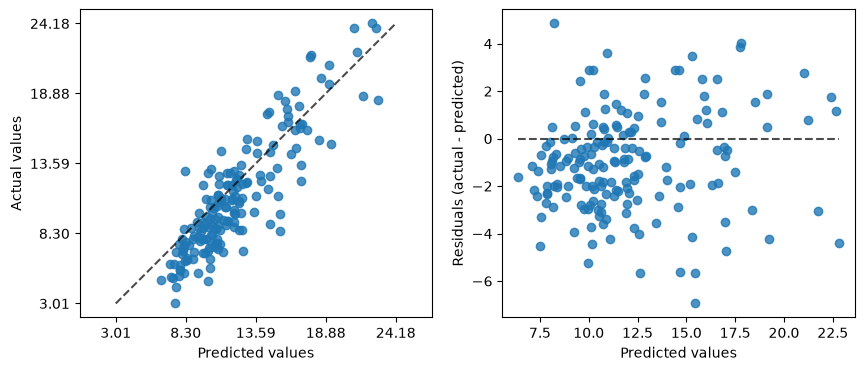

In [216]:
import matplotlib.pyplot as plt
from sklearn.metrics import PredictionErrorDisplay

fig, axs = plt.subplots(ncols=2, figsize=(10, 4))
PredictionErrorDisplay.from_predictions(test_answers, preds, kind="actual_vs_predicted", ax=axs[0])

PredictionErrorDisplay.from_predictions(test_answers, preds, kind="residual_vs_predicted", ax=axs[1])

plt.show()

Now, let's save the model! (if it is smart enough.)

In [217]:
if r2 > 0.5:
    with open('MyVeryOwnModelThatImVeryProudOvAndHelloIfUrReadingThis.pkl', mode='wb') as file:
        dump(model, file)
    with open('MyScalerForMyVeryOwnModelYayHappyFace', mode='wb') as file:
        dump(scaler, file)
    print("The Model and The Scaler were saved!")
else:
    print("The Model had a skill issue")

The Model and The Scaler were saved!


smol probelm: the weather data is 6 hrs ahead of the air quality data.

LARGE PROBLEM: the air quality data is missing 2 chunks:
 - 2026/06/16
    - I filled it in with:
    - 2026-06-16(the date), 0.00(the exremely inaccurate air quality)
    - the 0.00 is exremely not accurate data but like who really cares
 - 2025-06-06 to 2026-07-29
    - this is a whole two months of data. Here is my solution:
        - cut and paste the weather data for those 2 months somewhere else for now
        - make the remaining data line up
        - train the model
        - look cool by filling in that data with a trained model(if it has a high accuracy)


The model was doing really bad on Austin data.
 - when I made the model ignore the daylight time, the austin R squared score went from negative a hundred thousand all the way up to negative one!